# 04 — Core and Full Logistic Regression xG Models

This notebook builds two logistic regression expected-goals (xG) models and compares them on held-out data.

**Flow of the notebook**

1. Import the cleaned shot dataset (`shots_cleaned.csv`)
2. Inspect the data briefly
3. Split chronologically into training (2021/22–2023/24), validation (2024/25) and test (2025/26)
4. **Core model** (spatial features only): build → train on the training set → validate → retrain on training + validation
5. **Full model** (all features, including `is_penalty`): build → train on the training set → validate → retrain on training + validation
6. Test both retrained models on the 2025/26 test set, produce xG predictions and a comparison table
7. Plot shot-level heatmaps of predicted xG for both models on the test set

Each model is scored with three metrics: **Brier score** (lower is better), **log loss** (lower is better) and **ROC-AUC** (higher is better).

## 1. Import the cleaned dataset

Libraries, the random seed and the season split are defined in one place so the whole notebook can be re-run reproducibly. The cleaned dataset is located automatically, whether the notebook is run from the project root or from the `notebooks` folder. Each row is one shot; `result` is the target (1 = goal, 0 = no goal).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Arc

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Configuration
RANDOM_STATE = 42
TARGET = "result"
SEASON = "season"

TRAIN_SEASONS = ["2021/22", "2022/23", "2023/24"]
VAL_SEASONS = ["2024/25"]
TEST_SEASONS = ["2025/26"]

# Locate shots_cleaned.csv (Group Sprint 1/data/cleaned)
candidate_paths = [
    Path.cwd() / "data" / "cleaned" / "shots_cleaned.csv",
    Path.cwd().parent / "data" / "cleaned" / "shots_cleaned.csv",
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find data/cleaned/shots_cleaned.csv. "
        "Check the notebook working directory."
    )

# Figures are saved to Group Sprint 1/figures
FIGURES_DIR = DATA_PATH.parents[2] / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded: /home/jovyan/Data Science Toolbox/Group Sprint 1/data/cleaned/shots_cleaned.csv
Dimensions: 50,798 rows x 38 columns


## 2. Inspect the data

A brief check of the first rows, missing values, the target and the number of shots per season. The target must be binary. The incomplete 2026/27 season (only a handful of matches) is excluded from all modelling.

In [2]:
display(df.head())

print(f"Total missing values: {int(df.isna().sum().sum())}")
assert set(df[TARGET].unique()) <= {0, 1}, "result must be coded 1 = goal, 0 = no goal"

season_summary = df.groupby(SEASON)[TARGET].agg(
    shots="size", goals="sum", goal_rate="mean"
)
display(season_summary)

# Exclude the incomplete 2026/27 season
df = df[df[SEASON] != "2026/27"].copy()
print(f"\nRows after excluding 2026/27: {len(df):,}")

,is_home,team,season,xg,minute,result,x,y,angle_to_goal,is_assisted,...,last_action_foul,last_action_head_pass,last_action_lay_off,last_action_none,last_action_pass,last_action_rebound,last_action_standard,last_action_tackle,last_action_take_on,last_action_throughball
0,1,Brentford,2021/22,0.053464,10,0,109.560004,43.120001,0.714539,0,...,0,0,0,0,0,0,0,0,0,0
1,1,Brentford,2021/22,0.118297,11,0,108.960004,25.200000,0.288597,1,...,0,0,0,0,0,0,0,0,0,1
2,1,Brentford,2021/22,0.052145,21,1,104.880002,55.840002,0.275243,1,...,0,0,0,0,0,0,0,0,0,0
3,1,Brentford,2021/22,0.065706,27,0,97.439996,38.239999,0.364677,1,...,0,0,0,0,1,0,0,0,0,0
4,1,Brentford,2021/22,0.080691,29,0,107.039996,28.560001,0.376828,1,...,0,0,0,0,0,0,0,0,0,0


Total missing values: 0


,shots,goals,goal_rate
season,,,
2021/22,9741,1037,0.106457
2022/23,9598,1038,0.108148
2023/24,10474,1196,0.114188
2024/25,9844,1081,0.109813
2025/26,9483,1004,0.105874
2026/27,1658,170,0.102533



Rows after excluding 2026/27: 49,140


## 3. Chronological train / validation / test split

The data are split by season rather than randomly, because the model is meant to predict future shots from past ones.

| Split | Seasons | Purpose |
|---|---|---|
| Training | 2021/22, 2022/23, 2023/24 | fit the models |
| Validation | 2024/25 | assess each model, then add back into the training data for a final refit |
| Test | 2025/26 | final out-of-sample comparison, used only in section 6 |

In [3]:
train_df = df[df[SEASON].isin(TRAIN_SEASONS)].copy()
val_df = df[df[SEASON].isin(VAL_SEASONS)].copy()
test_df = df[df[SEASON].isin(TEST_SEASONS)].copy()

# Every shot must land in exactly one split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Seasons": [", ".join(TRAIN_SEASONS), ", ".join(VAL_SEASONS), ", ".join(TEST_SEASONS)],
    "Shots": [len(train_df), len(val_df), len(test_df)],
    "Goal rate": [d[TARGET].mean() for d in (train_df, val_df, test_df)],
})
display(split_summary)

,Split,Seasons,Shots,Goal rate
0,Training,"2021/22, 2022/23, 2023/24",29813,0.109717
1,Validation,2024/25,9844,0.109813
2,Test,2025/26,9483,0.105874


## 4. Core model (spatial features only)

The core model uses only where the shot was taken from. Three features are used:

- `dist_goal_line`: distance from the goal line, `120 - x`
- `lateral_offset`: absolute distance from the centre of the pitch width, `|y - 40|`
- `angle_to_goal`: the angle subtended by the goal, already in the cleaned dataset

The distance and offset features are calculated row by row from `x` and `y`, so creating them after the split does not leak any information between splits. The helper functions below are shared by the core and full models so both are built, trained and scored identically (standardised features, then logistic regression).

In [4]:
GOAL_X = 120   # goal line (pitch is 120 x 80)
GOAL_Y = 40    # centre of the goal

assert df["x"].between(0, GOAL_X).all(), "x is not on a 0-120 scale"
assert "angle_to_goal" in df.columns


def add_spatial_features(frame):
    out = frame.copy()
    out["dist_goal_line"] = GOAL_X - out["x"]
    out["lateral_offset"] = (out["y"] - GOAL_Y).abs()
    return out


def make_pipeline():
    # A fresh, unfitted model: standardise features, then logistic regression
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])


def score(y_true, p_pred, column):
    # Brier score, log loss and ROC-AUC for one set of predictions
    return pd.DataFrame({
        "Metric": ["Brier score", "Log loss", "ROC-AUC"],
        column: [
            brier_score_loss(y_true, p_pred),
            log_loss(y_true, p_pred, labels=[0, 1]),
            roc_auc_score(y_true, p_pred),
        ],
    }).set_index("Metric")


train_df = add_spatial_features(train_df)
val_df = add_spatial_features(val_df)
test_df = add_spatial_features(test_df)

CORE_FEATURES = ["dist_goal_line", "lateral_offset", "angle_to_goal"]
display(train_df[CORE_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
dist_goal_line,29813.0,17.098734,8.851219,0.360004,10.319998,15.600000,23.760004,84.600000
lateral_offset,29813.0,7.922557,5.646991,0.000000,3.120001,6.960001,12.320001,39.600000
angle_to_goal,29813.0,0.457417,0.278537,0.002059,0.270078,0.362723,0.564623,2.846825


### 4.1 Train the core model on the training set

In [5]:
core_model = make_pipeline()
core_model.fit(train_df[CORE_FEATURES], train_df[TARGET])
print(f"Core model fitted on {len(train_df):,} training shots")

Core model fitted on 29,813 training shots


### 4.2 Validate the core model (2024/25)

The training-only model predicts the validation season. These scores are the honest validation result for the core model.

In [6]:
core_val_pred = core_model.predict_proba(val_df[CORE_FEATURES])[:, 1]

core_val_metrics = score(val_df[TARGET], core_val_pred, "Core (validation)")
display(core_val_metrics.round(4))

,Core (validation)
Metric,
Brier score,0.0895
Log loss,0.3132
ROC-AUC,0.7182


### 4.3 Retrain the core model on training + validation

Once validated, the 2024/25 shots are added back into the training data and the model is refitted from scratch. This gives the final core model more recent data. It is not re-scored on the validation season, because it has now seen those shots.

In [7]:
train_val_df = pd.concat([train_df, val_df])

core_final = make_pipeline()
core_final.fit(train_val_df[CORE_FEATURES], train_val_df[TARGET])
print(f"Final core model fitted on {len(train_val_df):,} shots (2021/22 to 2024/25)")

Final core model fitted on 39,657 shots (2021/22 to 2024/25)


## 5. Full model (all features)

The full model uses every predictor in the cleaned dataset: the three spatial features plus shot type (`is_penalty`, `is_open_play`, `is_set_piece`, `from_corner`, `is_free_kick`), `is_assisted`, body part, the previous action, match minute, home/away and the score before the shot.

Excluded from the predictors:

- `result`: the target
- `xg`: Understat's own xG, which would leak a competing model into this one
- `x`, `y`: replaced by `dist_goal_line` and `lateral_offset`
- `season`, `team`: identifiers and split labels, not shot features
- `last_action_foul`: zero goals in only 80 observations, the category provides insufficient information to estimate a reliable coefficient using ordinary maximum-likelihood logistic regression.

In [8]:
NON_PREDICTORS = {TARGET, SEASON, "team", "xg", "x", "y", "last_action_foul"}
FULL_FEATURES = [c for c in train_df.columns if c not in NON_PREDICTORS]

assert "is_penalty" in FULL_FEATURES
assert set(CORE_FEATURES) <= set(FULL_FEATURES)
assert "xg" not in FULL_FEATURES and TARGET not in FULL_FEATURES
assert df[[c for c in FULL_FEATURES if c in df.columns]].notna().all().all(), "missing values in features"

print(f"{len(FULL_FEATURES)} features in the full model:")
print(FULL_FEATURES)

33 features in the full model:
['is_home', 'minute', 'angle_to_goal', 'is_assisted', 'is_penalty', 'is_open_play', 'is_set_piece', 'from_corner', 'is_free_kick', 'team_goals_before', 'opp_goals_before', 'score_diff', 'head', 'left_foot', 'other_body_part', 'right_foot', 'last_action_aerial', 'last_action_ball_recovery', 'last_action_ball_touch', 'last_action_chipped', 'last_action_cross', 'last_action_dispossessed', 'last_action_head_pass', 'last_action_lay_off', 'last_action_none', 'last_action_pass', 'last_action_rebound', 'last_action_standard', 'last_action_tackle', 'last_action_take_on', 'last_action_throughball', 'dist_goal_line', 'lateral_offset']


### 5.1 Train the full model on the training set

In [9]:
full_model = make_pipeline()
full_model.fit(train_df[FULL_FEATURES], train_df[TARGET])
print(f"Full model fitted on {len(train_df):,} training shots")

Full model fitted on 29,813 training shots


### 5.2 Validate the full model (2024/25)

In [10]:
full_val_pred = full_model.predict_proba(val_df[FULL_FEATURES])[:, 1]

full_val_metrics = score(val_df[TARGET], full_val_pred, "Full (validation)")
display(full_val_metrics.round(4))

,Full (validation)
Metric,
Brier score,0.0809
Log loss,0.2850
ROC-AUC,0.7821


### 5.3 Retrain the full model on training + validation

In [11]:
full_final = make_pipeline()
full_final.fit(train_val_df[FULL_FEATURES], train_val_df[TARGET])
print(f"Final full model fitted on {len(train_val_df):,} shots (2021/22 to 2024/25)")

Final full model fitted on 39,657 shots (2021/22 to 2024/25)


## 6. Test both models on 2025/26

The test season has not been used for any fitting or modelling decision. Both retrained models predict the probability of a goal (xG) for every test shot. The predictions are saved alongside Understat's xG for the group, then the two models are compared on the same three metrics.

In [12]:
core_test_pred = core_final.predict_proba(test_df[CORE_FEATURES])[:, 1]
full_test_pred = full_final.predict_proba(test_df[FULL_FEATURES])[:, 1]

xg_test = test_df[["season", "team", "is_penalty"]].copy()
xg_test.insert(0, "row_id", test_df.index)        # row number in the cleaned CSV
xg_test["core_xg"] = core_test_pred
xg_test["lr_xg"] = full_test_pred                 # full logistic regression
xg_test["understat_xg"] = test_df["xg"].to_numpy()
xg_test["goal"] = test_df[TARGET].to_numpy()

display(xg_test.head(10))

xg_test.to_csv("lr_xg_predictions_2025_26.csv", index=False)
print(f"Saved {len(xg_test):,} test predictions to lr_xg_predictions_2025_26.csv")

,row_id,season,team,is_penalty,core_xg,lr_xg,understat_xg,goal
39657,39657,2025/26,Liverpool,0,0.024145,0.021655,0.014601,0
39658,39658,2025/26,Liverpool,0,0.044031,0.046758,0.042656,0
39659,39659,2025/26,Liverpool,0,0.231955,0.091181,0.257975,0
39660,39660,2025/26,Liverpool,0,0.195955,0.074748,0.077662,0
39661,39661,2025/26,Liverpool,0,0.165835,0.263844,0.404091,1
39662,39662,2025/26,Liverpool,0,0.317572,0.283533,0.534849,0
39663,39663,2025/26,Liverpool,0,0.089038,0.110778,0.113376,0
39664,39664,2025/26,Liverpool,0,0.429773,0.183518,0.134705,0
39665,39665,2025/26,Liverpool,0,0.128272,0.159333,0.095707,1
39666,39666,2025/26,Liverpool,0,0.031462,0.018289,0.027151,0


Saved 9,483 test predictions to lr_xg_predictions_2025_26.csv


In [13]:
y_test = test_df[TARGET]

test_comparison = pd.concat(
    [score(y_test, core_test_pred, "Core"), score(y_test, full_test_pred, "Full")],
    axis=1,
)
test_comparison["Full - Core"] = test_comparison["Full"] - test_comparison["Core"]

print("Test-set comparison (2025/26):")
display(test_comparison.round(4))

Test-set comparison (2025/26):


,Core,Full,Full - Core
Metric,,,
Brier score,0.0875,0.0791,-0.0085
Log loss,0.3073,0.2815,-0.0258
ROC-AUC,0.7183,0.7715,0.0532


## 7. Shot heatmaps on the test set

Each point is one 2025/26 shot, placed at its pitch location and coloured by the model's predicted probability of a goal. The pitch is drawn vertically with the goal at the top. Both panels share one colour scale so the models can be compared directly. The scale is capped at 0.5 so that the many low-probability shots stay distinguishable; penalties (well above 0.5) show in the top colour. Points are drawn from lowest to highest probability so the most dangerous shots are never hidden underneath others.

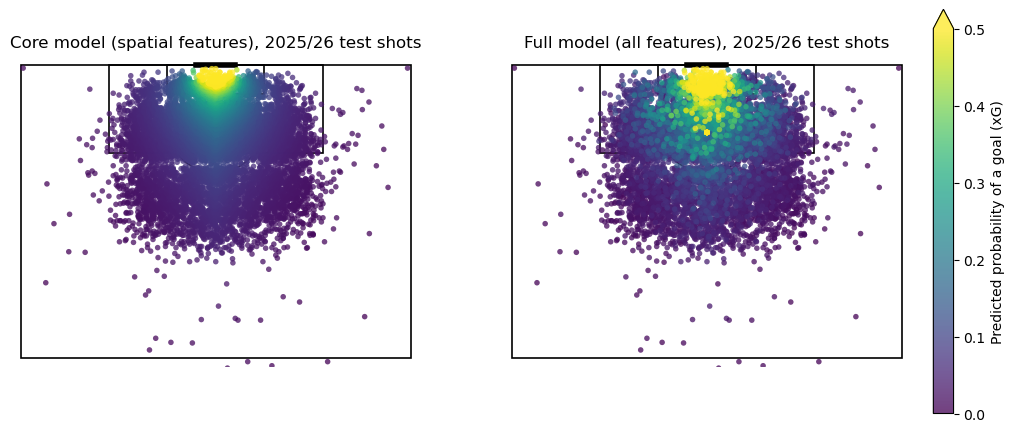

12 shots taken inside their own half are outside the plotted area.


In [14]:
def draw_half_pitch(ax):
    # Attacking half, goal at the top. Horizontal axis = y, vertical axis = x.
    line = dict(fill=False, color="black", linewidth=1.2)
    ax.add_patch(Rectangle((0, 60), 80, 60, **line))          # pitch outline
    ax.add_patch(Rectangle((18, 102), 44, 18, **line))        # penalty area
    ax.add_patch(Rectangle((30, 114), 20, 6, **line))         # six-yard box
    ax.add_patch(Arc((40, 108), 20, 20, theta1=217, theta2=323,
                     color="black", linewidth=1.2))           # penalty arc
    ax.scatter([40], [108], color="black", s=10, zorder=3)    # penalty spot
    ax.plot([36, 44], [120, 120], color="black", linewidth=4) # goal
    ax.set_xlim(-2, 82)
    ax.set_ylim(58, 122)
    ax.set_aspect("equal")
    ax.axis("off")


VMAX = 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, pred, title in zip(
    axes,
    [core_test_pred, full_test_pred],
    ["Core model (spatial features), 2025/26 test shots", "Full model (all features), 2025/26 test shots"],
):
    draw_half_pitch(ax)
    order = np.argsort(pred)   # draw high-probability shots last
    sc = ax.scatter(
        test_df["y"].to_numpy()[order],
        test_df["x"].to_numpy()[order],
        c=pred[order], cmap="viridis", vmin=0, vmax=VMAX,
        s=16, alpha=0.75, edgecolors="none", zorder=4,
    )
    ax.set_title(title)

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02, extend="max")
cbar.set_label("Predicted probability of a goal (xG)")

fig.savefig(FIGURES_DIR / "04_test_shot_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

n_hidden = int((test_df["x"] < 58).sum())
print(f"{n_hidden} shots taken inside their own half are outside the plotted area.")

### Feature Importance in the Full Logistic Regression Model

To examine the contribution of individual features to the full logistic regression model, the fitted coefficients are extracted and ranked according to their absolute magnitude. The ten features with the largest absolute coefficients are selected, retaining their original signs to distinguish between positive and negative associations with the probability of a goal.

The coefficients are plotted as a horizontal bar chart, with positive coefficients shown in blue and negative coefficients in red. Since the model uses standardised features, the coefficients represent the change in log-odds of a goal associated with a one standard deviation increase in the corresponding feature, holding all other features constant.

This provides an indication of which features have the strongest influence on the model's predictions and whether their relationship with the probability of scoring is positive or negative. However, coefficient magnitude should be interpreted as an indication of association rather than causation.

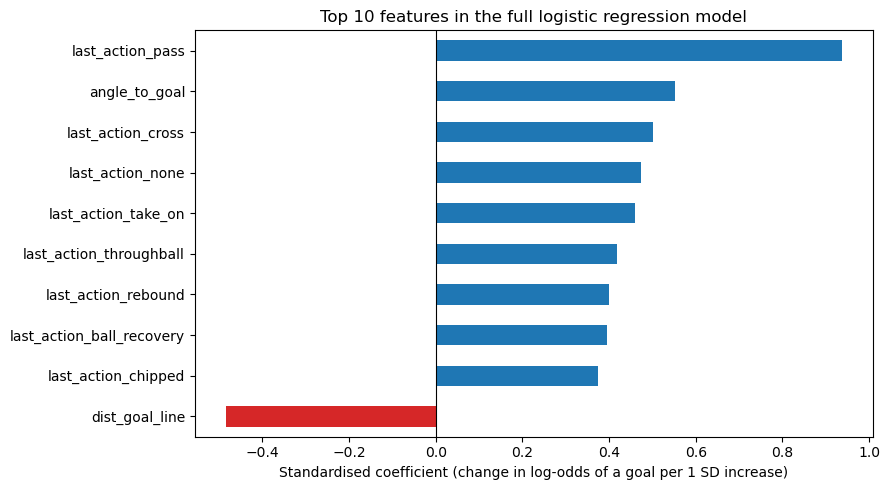

In [15]:
clf = full_final.named_steps["logit"]          # was full_model.named_steps["classifier"]
coef = pd.Series(clf.coef_[0], index=FULL_FEATURES)   # names come from FULL_FEATURES, so no get_feature_names_out / prefix stripping

# Ten largest coefficients by size, keeping their sign
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).sort_values()

plt.figure(figsize=(9, 5))
top.plot(kind="barh", color=["tab:red" if v < 0 else "tab:blue" for v in top])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardised coefficient (change in log-odds of a goal per 1 SD increase)")
plt.title("Top 10 features in the full logistic regression model")
plt.tight_layout()
plt.show()
 

In [16]:
import statsmodels.api as sm
from scipy import stats

tv = train_val_df.copy()

# Pool shots with no last-action flag (rare categories dropped in cleaning) with foul shots
LAST = [c for c in tv.columns if c.startswith("last_action_")]
tv["last_action_other"] = ((tv[LAST].sum(axis=1) == 0) | (tv["last_action_foul"] == 1)).astype(int)

# Reference categories (dropped) and continuous features (standardised)
# last_action_standard == is_penalty + is_free_kick exactly, so it is redundant
REFERENCE = ["score_diff", "is_open_play", "right_foot", "last_action_pass", "last_action_standard"]
CONT = ["minute", "angle_to_goal", "dist_goal_line", "lateral_offset",
        "team_goals_before", "opp_goals_before"]
feat = [c for c in FULL_FEATURES if c not in REFERENCE] + ["last_action_other"]

# Standardise continuous features only; leave dummies as 0/1
X = tv[feat].astype(float)
X[CONT] = (X[CONT] - X[CONT].mean()) / X[CONT].std()
X = sm.add_constant(X)
y = tv[TARGET]
assert np.linalg.matrix_rank(X.to_numpy()) == X.shape[1], "design matrix not full rank"

# Full model and nested core model
full_res = sm.Logit(y, X).fit(method="newton", maxiter=100, disp=False)
core_res = sm.Logit(y, sm.add_constant(X[CORE_FEATURES])).fit(method="newton", maxiter=100, disp=False)
assert full_res.mle_retvals["converged"] and core_res.mle_retvals["converged"], "did not converge"

# Tidy table
ci = full_res.conf_int()
fit_summary = pd.DataFrame({
    "Coefficient": full_res.params,
    "Std. error": full_res.bse,
    "z": full_res.tvalues,
    "p-value": full_res.pvalues,
    "Odds ratio": np.exp(full_res.params),
    "OR 2.5%": np.exp(ci[0]),
    "OR 97.5%": np.exp(ci[1]),
}).drop(index="const")
fit_summary["Scale"] = ["per 1 SD" if c in CONT else "0 -> 1" for c in fit_summary.index]
display(fit_summary.sort_values("z", key=abs, ascending=False).round(4))

# Likelihood-ratio test and model comparison
lr_stat = 2 * (full_res.llf - core_res.llf)
df_diff = int(full_res.df_model - core_res.df_model)
p_lr = stats.chi2.sf(lr_stat, df_diff)

comparison = pd.DataFrame({
    "Parameters": [int(core_res.df_model) + 1, int(full_res.df_model) + 1],
    "Log-likelihood": [core_res.llf, full_res.llf],
    "AIC": [core_res.aic, full_res.aic],
    "BIC": [core_res.bic, full_res.bic],
    "McFadden R2": [core_res.prsquared, full_res.prsquared],
}, index=["Core", "Full"])
display(comparison.round(4))
print(f"Likelihood-ratio test (full vs core): chi2 = {lr_stat:.1f}, df = {df_diff}, p = {p_lr:.2e}")

,Coefficient,Std. error,z,p-value,Odds ratio,OR 2.5%,OR 97.5%,Scale
angle_to_goal,0.5521,0.0265,20.8337,0.0000,1.7368,1.6489,1.8294,per 1 SD
is_penalty,2.7353,0.1622,16.8585,0.0000,15.4140,11.2152,21.1847,0 -> 1
dist_goal_line,-0.4854,0.0332,-14.6361,0.0000,0.6155,0.5767,0.6568,per 1 SD
lateral_offset,-0.3556,0.0286,-12.4171,0.0000,0.7008,0.6625,0.7412,per 1 SD
last_action_aerial,-1.1697,0.1058,-11.0507,0.0000,0.3105,0.2523,0.3820,0 -> 1
last_action_throughball,0.8373,0.0852,9.8229,0.0000,2.3100,1.9546,2.7300,0 -> 1
head,-0.5655,0.0698,-8.1043,0.0000,0.5681,0.4955,0.6513,0 -> 1
last_action_other,-2.0694,0.3242,-6.3822,0.0000,0.1263,0.0669,0.2384,0 -> 1
last_action_cross,-0.4306,0.0694,-6.2062,0.0000,0.6501,0.5674,0.7448,0 -> 1
team_goals_before,0.0879,0.0186,4.7226,0.0000,1.0919,1.0528,1.1325,per 1 SD


,Parameters,Log-likelihood,AIC,BIC,McFadden R2
Core,4,-12251.2096,24510.4192,24544.7712,0.1071
Full,30,-11139.3385,22338.6770,22596.3177,0.1881


Likelihood-ratio test (full vs core): chi2 = 2223.7, df = 26, p = 0.00e+00
